In [ ]:
!pip install -q scikit-learn imbalanced-learn transformers[torch] accelerate evaluate openpyxl wordcloud matplotlib seaborn


In [ ]:
import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import copy
from collections import Counter
from google.colab import drive, files
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from wordcloud import WordCloud



# Atur konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1.1 Mount Google Drive (Opsional jika file disimpan di Drive)
try:
    drive.mount('/content/drive')
    print("[INFO] Google Drive berhasil terhubung.")
except Exception as e:
    print(f"[INFO] Google Drive tidak terhubung ({e}). Menggunakan penyimpanan lokal/Colab.")

# 1.2 Pencarian File Dataset data_suwung_setelah dipilah.xlsx
candidate_paths = [
    '/content/drive/MyDrive/INDOBERT/data_suwung_setelah dipilah.xlsx',
    'data_suwung_setelah dipilah.xlsx',
    '/content/data_suwung_setelah dipilah.xlsx',
    '../data_suwung_setelah dipilah.xlsx'
]

dataset_path = None
for path in candidate_paths:
    if os.path.exists(path):
        dataset_path = path
        break

if dataset_path is None:
    print("[PERINGATAN] File 'data_suwung_setelah dipilah.xlsx' belum ditemukan di path otomatis.")
    print("Silakan unggah file melalui jendela upload di bawah ini:")
    uploaded = files.upload()
    for fname in uploaded.keys():
        if fname.endswith(('.xlsx', '.xls')):
            dataset_path = fname
            break

print(f"[SUKSES] Memuat dataset dari: {dataset_path}")
df_raw = pd.read_excel(dataset_path)

# Standardisasi Nama Kolom
if 'Komentar Asli (Raw Data)' in df_raw.columns:
    col_text = 'Komentar Asli (Raw Data)'
elif 'Komentar' in df_raw.columns:
    col_text = 'Komentar'
else:
    col_text = df_raw.columns[1]

if 'No' in df_raw.columns:
    col_id = 'No'
else:
    df_raw['No'] = np.arange(1, len(df_raw) + 1)
    col_id = 'No'

df_loaded = pd.DataFrame({
    'ID_Komentar': df_raw[col_id],
    'Komentar_Asli': df_raw[col_text].astype(str)
})

print(f"Total baris dataset berhasil dimuat: {len(df_loaded)} baris komentar TikTok TPA Suwung.")
display(df_loaded.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[INFO] Google Drive berhasil terhubung.
[SUKSES] Memuat dataset dari: /content/drive/MyDrive/INDOBERT/data_suwung_setelah dipilah.xlsx
Total baris dataset berhasil dimuat: 1202 baris komentar TikTok TPA Suwung.


,ID_Komentar,Komentar_Asli
0,1,Terus ke mana kami buang sampah organic?
1,2,ije ngalih pis anggo meli alat ne
2,3,solusi buat anak kost ?
3,4,kenapa ga pemerintah aja yang nyiapin alat ola...
4,5,brtahun tahun di bali iuran sampah 20k /bln si...


In [ ]:
bali_normalization = {
    # Negasi Bahasa Bali (Krusial agar polaritas sentimen InSet & IndoBERT akurat)
    'sing': 'tidak', 'sg': 'tidak', 'seng': 'tidak', 'tusing': 'tidak',
    'ten': 'tidak', 'tan': 'tidak',
    'de': 'jangan', 'da': 'jangan', 'ede': 'jangan',
    'konden': 'belum', 'kondn': 'belum', 'durung': 'belum', 'tondene': 'sebelumnya',

    # Kata Tanya & Arah / Lokasi
    'ije': 'ke mana', 'dije': 'di mana', 'kije': 'ke mana', 'kijo': 'ke mana', 'dje': 'di mana',
    'kenken': 'bagaimana', 'engken': 'bagaimana', 'engkn': 'bagaimana', 'punapi': 'bagaimana',
    'ngujang': 'buat apa', 'ngudyang': 'buat apa',
    'nyen': 'siapa', 'sira': 'siapa', 'sire': 'siapa',
    'ape': 'apa', 'napi': 'apa',
    'dini': 'di sini', 'ditu': 'di sana', 'mai': 'ke sini', 'kemu': 'ke sana', 'ija': 'ke mana',

    # Kata Terkait Sampah, Uang, & Lingkungan
    'lulu': 'sampah', 'lulune': 'sampahnya', 'luu': 'sampah', 'mis': 'sampah',
    'pis': 'uang', 'pise': 'uangnya', 'pipis': 'uang', 'jinah': 'uang',
    'umah': 'rumah', 'umahne': 'rumahnya', 'peken': 'pasar', 'tebe': 'pekarangan',
    'gumi': 'bumi', 'don': 'daun', 'jukut': 'sayur',
    'bengu': 'bau busuk', 'boonne': 'baunya', 'getih': 'darah', 'barak': 'merah',
    'kuluk': 'anjing', 'bangken': 'bangkai', 'cicing': 'anjing',

    # Kata Kerja (Tindakan & Aktivitas)
    'ngutang': 'buang', 'kutang': 'buang',
    'ngalih': 'cari', 'alih': 'cari', 'alihang': 'carikan',
    'meli': 'beli', 'mayah': 'bayar', 'bayah': 'bayar',
    'ngae': 'buat', 'ngaenang': 'membuatkan', 'gaene': 'pekerjaannya', 'gegaen': 'pekerjaan', 'megae': 'bekerja',
    'baang': 'beri', 'bang': 'beri', 'maang': 'memberi', 'ngemang': 'memberi',
    'ngorin': 'menyuruh', 'orin': 'suruh', 'orine': 'disuruh', 'tunden': 'suruh',
    'memunyi': 'berbicara', 'munyi': 'bicara', 'munyine': 'bicaranya',
    'ngorahang': 'mengatakan', 'orahang': 'katakan', 'metakon': 'bertanya',
    'nengil': 'diam', 'meneng': 'diam',
    'ngukir': 'mengukir', 'ukire': 'diukir', 'ngamah': 'makan',
    'suud': 'selesai', 'kel': 'akan', 'kal': 'akan', 'lakar': 'akan',
    'nyidang': 'bisa', 'ngidang': 'bisa', 'bise': 'bisa', 'maan': 'dapat', 'polih': 'dapat',
    'mragatin': 'menyelesaikan', 'pragat': 'selesai',
    'nolih': 'melihat', 'tepuk': 'terlihat', 'jemak': 'ambil',
    'ngitungan': 'menghiraukan', 'nyalanang': 'menjalankan',
    'kedek': 'tertawa', 'mecande': 'bercanda', 'melajah': 'belajar',
    'pesuang': 'keluarkan', 'kejang': 'semua', 'nampung': 'menampung',
    'mulih': 'pulang', 'mulihne': 'pulangnya', 'meabe': 'dibawa', 'abe': 'bawa', 'ngabe': 'membawa',
    'metutup': 'tertutup', 'dadiang': 'jadikan', 'kelakuang': 'diperlakukan',
    'kaaba': 'dibawa', 'ngurusang': 'mengurus', 'ngendah': 'berulah',

    # Kata Ganti, Panggilan & Sapaan
    'tiang': 'saya', 'titiang': 'saya', 'tyg': 'saya', 'tyang': 'saya',
    'cang': 'saya', 'icang': 'saya', 'awake': 'kita', 'ragane': 'anda', 'rage': 'kita',
    'ci': 'kamu', 'cai': 'kamu', 'iba': 'kamu',
    'ye': 'dia', 'iye': 'dia',
    'nak': 'orang', 'anake': 'orangnya',
    'bli': 'kakak', 'mbok': 'mbak',
    'pekak': 'kakek', 'dadong': 'nenek',
    'pakyan': 'pak wayan',

    # Kata Sifat, Karakter & Kondisi
    'lengeh': 'bodoh', 'belog': 'bodoh', 'buduh': 'gila',
    'kedas': 'bersih', 'kumuh': 'kumuh',
    'sebet': 'sedih', 'demen': 'senang', 'jejeh': 'takut',
    'keweh': 'susah', 'aluh': 'gampang', 'soleh': 'aneh',
    'usak': 'rusak', 'nyag': 'hancur', 'uwug': 'hancur',
    'aeng': 'hebat', 'beneh': 'benar', 'pelih': 'salah',
    'luung': 'bagus', 'melah': 'bagus', 'dueg': 'pintar',
    'asbun': 'asal bunyi', 'pocol': 'rugi', 'lengit': 'malas',
    'jengah': 'geram', 'pedih': 'marah', 'gedeg': 'jengkel',

    # Keterangan, Partikel & Kuantitas
    'gen': 'saja', 'dogen': 'saja', 'doen': 'saja', 'manten': 'saja',
    'ne': 'ini', 'to': 'itu', 'ento': 'itu', 'ene': 'ini',
    'kene': 'begini', 'keto': 'begitu',
    'jani': 'sekarang', 'jny': 'sekarang', 'pidan': 'dulu', 'ibi': 'kemarin', 'mani': 'besok',
    'suba': 'sudah', 'sube': 'sudah', 'be': 'sudah',
    'kadung': 'terlanjur', 'kadong': 'terlanjur',
    'ade': 'ada', 'dadi': 'jadi',
    'anggo': 'untuk', 'anggon': 'untuk', 'anggone': 'untuknya',
    'pang': 'biar', 'apang': 'agar',
    'men': 'kalau', 'amen': 'kalau', 'lamun': 'kalau', 'yen': 'kalau',
    'liu': 'banyak', 'liunan': 'kebanyakan', 'lebian': 'kebanyakan',
    'makejang': 'semuanya', 'mekejang': 'semuanya',
    'saje': 'benar', 'sajan': 'sekali', 'seken': 'benar', 'ajan': 'sekali', 'gati': 'sekali',
    'bes': 'terlalu', 'gebuh': 'banyak omong', 'pedidi': 'sendiri',
    'kone': 'katanya', 'nggih': 'ya', 'ngih': 'ya', 'ngihhh': 'ya', 'mare': 'baru',
    'paek': 'dekat', 'suksma': 'terima kasih', 'sukseme': 'terima kasih',
    'mirib': 'mungkin', 'jeg': 'langsung', 'nok': 'deh', 'nah': 'ya',
    'mule': 'memang', 'mula': 'memang', 'jak': 'dengan',
    'tongos': 'tempat', 'kanti': 'sampai', 'unduk': 'hal', 'unduke': 'halnya', 'megenep': 'macam-macam', 'bin': 'lagi', 'misi': 'tambah', 'uleh': 'akal', 'mebalih': 'menonton', 'ane': 'yang', 'ani': 'yang', 'yo': 'dia', 'kar': 'akan',
    'mekacakan': 'berantakan', 'kaden': 'kira'
}

# 2.2 Kamus Slang & Singkatan Bahasa Indonesia
slang_indo = {
    'yg': 'yang', 'dgn': 'dengan', 'sy': 'saya', 'gw': 'saya', 'gue': 'saya',
    'lu': 'kamu', 'lo': 'kamu', 'bgt': 'banget', 'klo': 'kalau', 'kl': 'kalau',
    'tp': 'tapi', 'tpi': 'tapi', 'jd': 'jadi', 'jdi': 'jadi', 'trs': 'terus',
    'trus': 'terus', 'udh': 'sudah', 'sdh': 'sudah', 'dah': 'sudah',
    'blm': 'belum', 'belom': 'belum', 'bkn': 'bukan', 'jgn': 'jangan',
    'sm': 'sama', 'sma': 'sama', 'org': 'orang', 'gmn': 'gimana', 'gmna': 'gimana',
    'utk': 'untuk', 'dpt': 'dapat', 'bnyk': 'banyak', 'byk': 'banyak',
    'byr': 'bayar', 'aja': 'saja', 'aj': 'saja', 'gak': 'tidak', 'ga': 'tidak',
    'gk': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'tdk': 'tidak',
    'tak': 'tidak', 'kpd': 'kepada', 'dr': 'dari', 'dri': 'dari',
    'tau': 'tahu', 'ilang': 'hilang', 'krn': 'karena', 'karna': 'karena',
    'ttg': 'tentang', 'mslh': 'masalah', 'smph': 'sampah', 'bs': 'bisa',
    'bisaa': 'bisa', 'skrg': 'sekarang', 'skg': 'sekarang', 'ttup': 'tutup',
    'ditutop': 'ditutup', 'bikin': 'buat', 'ngasi': 'memberi', 'kasi': 'memberi',
    'mn': 'kalau', 'lgsg': 'langsung'
}

# 2.3 Fungsi Pembersihan & Normalisasi Terpadu
def clean_and_normalize(text):
    if not isinstance(text, str):
        return ""

    # 1. Case Folding
    text = text.lower()

    # 2. Hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # 3. Hapus Mention (@username) dan Tagar (#hashtag)
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'#\w+', ' ', text)

    # 4. Hapus Karakter Non-Alphanumeric (Tanda baca diubah menjadi spasi)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    # 5. Tokenisasi & Penggantian Kata Berbasis Kamus
    tokens = text.split()
    normalized_tokens = []
    for t in tokens:
        # Cek slang Indonesia dulu
        if t in slang_indo:
            t = slang_indo[t]
        # Cek kamus normalisasi bahasa Bali
        elif t in bali_normalization:
            t = bali_normalization[t]
        # Tangani sufiks kepemilikan bahasa Bali '-ne' (misal: solusine -> solusinya)
        elif t.endswith('ne') and len(t) > 4:
            base = t[:-2]
            if base in ['solusi', 'sampah', 'alat', 'gubernur', 'kebijakan', 'pejabat', 'masyarakat', 'bapak', 'truk', 'program', 'kantor']:
                t = base + 'nya'
            elif base in bali_normalization:
                t = bali_normalization[base] + 'nya'
        normalized_tokens.append(t)

    # 6. Normalisasi Spasi Berlebih
    return ' '.join(normalized_tokens).strip()

# Alias fungsi agar kompatibel di seluruh notebook
clean_text_preserving_negations = clean_and_normalize

# Terapkan Normalisasi ke Seluruh Dataset
df_loaded['Komentar_Bersih'] = df_loaded['Komentar_Asli'].apply(clean_and_normalize)
df_loaded = df_loaded[df_loaded['Komentar_Bersih'].str.len() > 0].reset_index(drop=True)

# 2.4 Evaluasi Hasil Normalisasi Bahasa Bali
contoh_bali_eval = []
for idx, row in df_loaded.iterrows():
    orig_words = set(re.findall(r'\b[a-zA-Z]+\b', row['Komentar_Asli'].lower()))
    found_bali = [w for w in orig_words if w in bali_normalization]
    if found_bali:
        contoh_bali_eval.append({
            'ID': row['ID_Komentar'],
            'Kata_Bali_Terdeteksi': ', '.join(found_bali[:4]),
            'Komentar_Asli': row['Komentar_Asli'],
            'Komentar_Ternormalisasi': row['Komentar_Bersih']
        })

df_bali_eval = pd.DataFrame(contoh_bali_eval)
print(f"[SUKSES] Total komentar mengandung kosakata bahasa Bali: {len(df_bali_eval)} baris.")
print(f"Total baris valid setelah preprocessing & normalisasi: {len(df_loaded)} baris.")
print("""
--- 10 CONTOH NORMALISASI KOMENTAR BAHASA BALI KE BAHASA INDONESIA ---""")
display(df_bali_eval.head(10))

[SUKSES] Total komentar mengandung kosakata bahasa Bali: 259 baris.
Total baris valid setelah preprocessing & normalisasi: 1202 baris.

--- 10 CONTOH NORMALISASI KOMENTAR BAHASA BALI KE BAHASA INDONESIA ---


,ID,Kata_Bali_Terdeteksi,Komentar_Asli,Komentar_Ternormalisasi
0,2,"ne, ngalih, anggo, ije",ije ngalih pis anggo meli alat ne,ke mana cari uang untuk beli alat ini
1,20,nggih,terus sampah nya di bawa ke mana nggih pak… ka...,terus sampah nya di bawa ke mana ya pak kasih ...
2,22,"ngihhh, ne, ten, manten","Ngihhh pak yan bagus, tyg pribadi ten masalah ...",ya pak yan bagus saya pribadi tidak masalah tp...
3,26,"ade, ne, sing, doen",pak ne sebatas ngomong doen sing ade solusi ne,pak ini sebatas ngomong saja tidak ada solusi ini
4,30,"engkn, sing, nah","Nah sing engkn ttup,trus solusine apa?",ya tidak bagaimana tutup terus solusinya apa
5,45,"ne, anggo","Sampah plastik ne anggo krupuk, sampah daun an...",sampah plastik ini untuk krupuk sampah daun un...
6,57,nah,nah setelah di pilah di bawa kemana? apalagi a...,ya setelah di pilah di bawa kemana apalagi ana...
7,65,bli,minta koster bli solusinya,minta koster kakak solusinya
8,84,bli,bantu jwb ..disuruh mikir sendiri bli,bantu jwb disuruh mikir sendiri kakak
9,89,"ne, alihang, seken, dje","mn seken tutup lgsg tutup pak yan, alihang sol...",kalau benar tutup langsung tutup pak yan carik...


In [ ]:
aspect_keywords = {
    "Kebijakan Pemerintah": [
        "pemerintah", "pemkot", "pemprov", "walikota", "wali kota", "gubernur",
        "dprd", "dinas", "kebijakan", "aturan", "peraturan", "larangan",
        "penutupan", "ditutup", "menutup", "buka", "dibuka", "keputusan",
        "regulasi", "pemda", "koster", "jaya negara", "aparat", "instruksi",
        "solusi pemerintah", "sidak", "kebijakan pemerintah", "perda"
    ],
    "Infrastruktur Pengolahan": [
        "tpa", "tempat pembuangan akhir", "pengolahan", "pengelolaan", "sampah",
        "fasilitas", "infrastruktur", "mesin", "alat", "teknologi", "daur ulang",
        "recycle", "pemilahan", "pembuangan", "pengangkutan", "armada", "truk",
        "truk sampah", "bak sampah", "kontainer", "tpst", "suwung", "organik",
        "anorganik", "incinerator", "residu", "bank sampah", "sistem olah"
    ],
    "Dampak Lingkungan": [
        "lingkungan", "pencemaran", "polusi", "bau", "busuk", "sungai", "laut",
        "air", "tanah", "udara", "banjir", "limbah", "emisi", "gas", "metana",
        "ekosistem", "kebersihan", "lalat", "kotor", "asap", "kumuh", "penyakit",
        "kesehatan", "pencemaran lingkungan", "kebakaran", "udara kotor"
    ],
    "Beban Masyarakat": [
        "masyarakat", "warga", "rakyat", "penduduk", "beban", "biaya", "ongkos",
        "iuran", "retribusi", "rumah", "pedagang", "usaha", "umkm", "bali",
        "kost", "kos", "anak kost", "bayar", "beli", "uang", "rugi", "merugikan",
        "kesulitan", "susah", "mengeluh", "keluhan warga", "beban masyarakat"
    ]
}

# Kamus Sentimen InSet (Indonesian Sentiment Lexicon) disesuaikan dengan konteks TPA Suwung
positive_words = set([
    "baik", "bagus", "positif", "setuju", "mendukung", "dukung", "mantap", "hebat",
    "solusi", "berhasil", "sukses", "efektif", "efisien", "bersih", "aman", "sehat",
    "maju", "apresiasi", "terima kasih", "semoga", "mudah mudahan", "keren", "rapi",
    "tertib", "bermanfaat", "puas", "senang", "tepat", "teratasi", "bisa", "sepakat",
    "bijak", "terobosan", "menjanjikan", "berjalan"
])

negative_words = set([
    "buruk", "jelek", "negatif", "tidak setuju", "menolak", "tolak", "gagal", "masalah",
    "bermasalah", "parah", "kacau", "sulit", "susah", "mahal", "merugikan", "dirugikan",
    "beban", "pencemaran", "polusi", "bau", "busuk", "kotor", "banjir", "limbah", "bahaya",
    "berbahaya", "mengganggu", "ganggu", "kecewa", "kejahatan", "korupsi", "tidak mampu",
    "tidak efektif", "tidak jelas", "semrawut", "sia sia", "percuma", "kumuh", "bohong",
    "keluhan", "lambat", "lelet", "ribet", "bingung", "kecewa", "hancur", "terlantar",
    "menumpuk", "resah", "rusak", "rugi", "dosa", "mematikan", "sampah berserakan"
])

# Daftar kata negasi lengkap
negation_words = set([
    "tidak", "tak", "bukan", "jangan", "belum", "nggak", "gak", "ga", "kurang", "ndak"
])

def detect_sentiment_inset(text):
    tokens = text.split()
    pos_score = 0
    neg_score = 0
    i = 0

    while i < len(tokens):
        word = tokens[i]
        # Pengecekan Negasi (Membalik polaritas kata berikutnya)
        if word in negation_words and (i + 1) < len(tokens):
            next_word = tokens[i + 1]
            if next_word in positive_words:
                neg_score += 1.5
                i += 2
                continue
            elif next_word in negative_words:
                pos_score += 1.5
                i += 2
                continue

        if word in positive_words:
            pos_score += 1.0
        elif word in negative_words:
            neg_score += 1.0
        i += 1

    if pos_score > neg_score:
        return "Positif"
    elif neg_score > pos_score:
        return "Negatif"
    else:
        return "Netral"

print("Kamus 4 Aspek TPA Suwung dan Sentimen InSet siap digunakan.")


Kamus 4 Aspek TPA Suwung dan Sentimen InSet siap digunakan.


In [ ]:
joint_task_mapping = {
    "Kebijakan Pemerintah_Positif": 0,
    "Kebijakan Pemerintah_Negatif": 1,
    "Kebijakan Pemerintah_Netral": 2,
    "Infrastruktur Pengolahan_Positif": 3,
    "Infrastruktur Pengolahan_Negatif": 4,
    "Infrastruktur Pengolahan_Netral": 5,
    "Dampak Lingkungan_Positif": 6,
    "Dampak Lingkungan_Negatif": 7,
    "Dampak Lingkungan_Netral": 8,
    "Beban Masyarakat_Positif": 9,
    "Beban Masyarakat_Negatif": 10,
    "Beban Masyarakat_Netral": 11
}

joint_task_id_to_label = {v: k for k, v in joint_task_mapping.items()}

pairs = []
for idx, row in df_loaded.iterrows():
    c_id = row['ID_Komentar']
    raw_txt = row['Komentar_Asli']
    clean_txt = row['Komentar_Bersih']

    # Deteksi aspek berdasarkan kata kunci
    detected = []
    for aspect, kws in aspect_keywords.items():
        for kw in kws:
            pattern = r'\b' + re.escape(kw) + r'\b'
            if re.search(pattern, clean_txt):
                detected.append(aspect)
                break

    # Poin 3: Jika tidak terdeteksi aspek, EKSKLUSI (jangan otomatis netral)
    if not detected:
        continue

    # Hitung sentimen komentar
    sent = detect_sentiment_inset(clean_txt)

    # Bentuk pasangan komentar–aspek
    for asp in detected:
        joint_lbl = f"{asp}_{sent}"
        pairs.append({
            'ID_Komentar': c_id,
            'Komentar_Asli': raw_txt,
            'Komentar_Bersih': clean_txt,
            'Aspek': asp,
            'Sentimen': sent,
            'Joint_Label': joint_lbl,
            'Joint_Label_ID': joint_task_mapping[joint_lbl]
        })

df_pairs = pd.DataFrame(pairs)
print("=" * 70)
print("HASIL PEMBENTUKAN PASANGAN KOMENTAR–ASPEK (TPA SUWUNG)")
print("=" * 70)
print(f"Total komentar asli yang diproses : {len(df_loaded)}")
print(f"Jumlah komentar memiliki aspek    : {df_pairs['ID_Komentar'].nunique()} (Komentar tanpa aspek dieksklusi)")
print(f"Total pasangan komentar–aspek     : {len(df_pairs)} baris pasangan")
print("=" * 70)

# Simpan dataset pasangan ke Excel
output_pairs_excel = "dataset_pasangan_komentar_aspek_suwung.xlsx"
df_pairs.to_excel(output_pairs_excel, index=False)
print(f"[TERSIMPAN] Dataset pasangan diekspor ke: {output_pairs_excel}")
display(df_pairs.head(10))


HASIL PEMBENTUKAN PASANGAN KOMENTAR–ASPEK (TPA SUWUNG)
Total komentar asli yang diproses : 1202
Jumlah komentar memiliki aspek    : 944 (Komentar tanpa aspek dieksklusi)
Total pasangan komentar–aspek     : 1376 baris pasangan
[TERSIMPAN] Dataset pasangan diekspor ke: dataset_pasangan_komentar_aspek_suwung.xlsx


,ID_Komentar,Komentar_Asli,Komentar_Bersih,Aspek,Sentimen,Joint_Label,Joint_Label_ID
0,1,Terus ke mana kami buang sampah organic?,terus ke mana kami buang sampah organic,Infrastruktur Pengolahan,Netral,Infrastruktur Pengolahan_Netral,5
1,2,ije ngalih pis anggo meli alat ne,ke mana cari uang untuk beli alat ini,Infrastruktur Pengolahan,Netral,Infrastruktur Pengolahan_Netral,5
2,2,ije ngalih pis anggo meli alat ne,ke mana cari uang untuk beli alat ini,Beban Masyarakat,Netral,Beban Masyarakat_Netral,11
3,3,solusi buat anak kost ?,solusi buat anak kost,Beban Masyarakat,Positif,Beban Masyarakat_Positif,9
4,4,kenapa ga pemerintah aja yang nyiapin alat ola...,kenapa tidak pemerintah saja yang nyiapin alat...,Kebijakan Pemerintah,Negatif,Kebijakan Pemerintah_Negatif,1
5,4,kenapa ga pemerintah aja yang nyiapin alat ola...,kenapa tidak pemerintah saja yang nyiapin alat...,Infrastruktur Pengolahan,Negatif,Infrastruktur Pengolahan_Negatif,4
6,4,kenapa ga pemerintah aja yang nyiapin alat ola...,kenapa tidak pemerintah saja yang nyiapin alat...,Beban Masyarakat,Negatif,Beban Masyarakat_Negatif,10
7,5,brtahun tahun di bali iuran sampah 20k /bln si...,brtahun tahun di bali iuran sampah 20k bln sia...,Infrastruktur Pengolahan,Netral,Infrastruktur Pengolahan_Netral,5
8,5,brtahun tahun di bali iuran sampah 20k /bln si...,brtahun tahun di bali iuran sampah 20k bln sia...,Beban Masyarakat,Netral,Beban Masyarakat_Netral,11
9,6,paling bener difasilitasi untuk pembuangan sam...,paling bener difasilitasi untuk pembuangan sam...,Infrastruktur Pengolahan,Netral,Infrastruktur Pengolahan_Netral,5


In [ ]:
tabel_distribusi_asli = pd.crosstab(
    df_pairs['Aspek'],
    df_pairs['Sentimen'],
    margins=True,
    margins_name='Total'
)

# Pastikan urutan kolom: Positif, Negatif, Netral, Total
cols_order = [c for c in ['Positif', 'Negatif', 'Netral', 'Total'] if c in tabel_distribusi_asli.columns]
tabel_distribusi_asli = tabel_distribusi_asli[cols_order]

print("=" * 70)
print("TABEL 3.x DISTRIBUSI OPINI 4 KATEGORI ASPEK (SEBELUM PENYEIMBANGAN)")
print("=" * 70)
display(tabel_distribusi_asli)

# Tampilkan juga distribusi 12 Joint Label sesuai Tabel 3.8 Laporan Skripsi
joint_dist = df_pairs['Joint_Label'].value_counts().reindex(list(joint_task_mapping.keys()), fill_value=0)
df_joint_dist = pd.DataFrame({
    'Label Numerik': [joint_task_mapping[k] for k in joint_dist.index],
    'Label Gabungan (Joint Label)': joint_dist.index,
    'Jumlah Sampel': joint_dist.values,
    'Persentase (%)': np.round(joint_dist.values / len(df_pairs) * 100, 2)
})

print(); print( "=" * 70)
print("DISTRIBUSI 12 KELAS JOINT TASK SESUAI TABEL 3.8 LAPORAN SKRIPSI")
print("=" * 70)
display(df_joint_dist)


TABEL 3.x DISTRIBUSI OPINI 4 KATEGORI ASPEK (SEBELUM PENYEIMBANGAN)


Sentimen,Positif,Negatif,Netral,Total
Aspek,,,,
Beban Masyarakat,76,63,164,303
Dampak Lingkungan,5,57,25,87
Infrastruktur Pengolahan,110,96,454,660
Kebijakan Pemerintah,111,36,179,326
Total,302,252,822,1376



DISTRIBUSI 12 KELAS JOINT TASK SESUAI TABEL 3.8 LAPORAN SKRIPSI


,Label Numerik,Label Gabungan (Joint Label),Jumlah Sampel,Persentase (%)
0,0,Kebijakan Pemerintah_Positif,111,8.07
1,1,Kebijakan Pemerintah_Negatif,36,2.62
2,2,Kebijakan Pemerintah_Netral,179,13.01
3,3,Infrastruktur Pengolahan_Positif,110,7.99
4,4,Infrastruktur Pengolahan_Negatif,96,6.98
5,5,Infrastruktur Pengolahan_Netral,454,32.99
6,6,Dampak Lingkungan_Positif,5,0.36
7,7,Dampak Lingkungan_Negatif,57,4.14
8,8,Dampak Lingkungan_Netral,25,1.82
9,9,Beban Masyarakat_Positif,76,5.52


In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df_pairs, groups=df_pairs['ID_Komentar']))

train_df = df_pairs.iloc[train_idx].copy().reset_index(drop=True)
test_df = df_pairs.iloc[test_idx].copy().reset_index(drop=True)

# BUKTI MATEMATIS BEBAS DATA LEAKAGE (ZERO OVERLAP):
train_comments = set(train_df['ID_Komentar'])
test_comments = set(test_df['ID_Komentar'])
overlap_check = train_comments.intersection(test_comments)

print("=" * 70)
print("VERIFIKASI PEMBAGIAN DATASET (80:20 GROUP SPLIT)")
print("=" * 70)
print(f"Jumlah Komentar Unik di Data Latih : {len(train_comments)} ID ({len(train_comments)/df_pairs['ID_Komentar'].nunique()*100:.1f}%)")
print(f"Jumlah Komentar Unik di Data Uji   : {len(test_comments)} ID ({len(test_comments)/df_pairs['ID_Komentar'].nunique()*100:.1f}%)")
print(f"Baris Pasangan Data Latih (Train)  : {len(train_df)} baris ({len(train_df)/len(df_pairs)*100:.1f}%)")
print(f"Baris Pasangan Data Uji (Test)     : {len(test_df)} baris ({len(test_df)/len(df_pairs)*100:.1f}%)")
print(f"Komentar Tumpang Tindih (Overlap)  : {len(overlap_check)} komentar")
print("=" * 70)

if len(overlap_check) == 0:
    print("[TERBUKTI] ZERO DATA LEAKAGE: Tidak ada satupun komentar yang berada di Data Latih sekaligus Data Uji!")
else:
    raise AssertionError("[ERROR] Ditemukan kebocoran data antar kelompok!")


VERIFIKASI PEMBAGIAN DATASET (80:20 GROUP SPLIT)
Jumlah Komentar Unik di Data Latih : 755 ID (80.0%)
Jumlah Komentar Unik di Data Uji   : 189 ID (20.0%)
Baris Pasangan Data Latih (Train)  : 1105 baris (80.3%)
Baris Pasangan Data Uji (Test)     : 271 baris (19.7%)
Komentar Tumpang Tindih (Overlap)  : 0 komentar
[TERBUKTI] ZERO DATA LEAKAGE: Tidak ada satupun komentar yang berada di Data Latih sekaligus Data Uji!


In [ ]:
print("Distribusi Sentimen Data Latih SEBELUM Penyeimbangan:")
dist_train_before = train_df['Sentimen'].value_counts()
print(dist_train_before)

# Terapkan RandomOverSampler pada data latih
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(
    train_df[['ID_Komentar', 'Komentar_Asli', 'Komentar_Bersih', 'Aspek', 'Joint_Label', 'Joint_Label_ID']],
    train_df['Sentimen']
)

train_df_balanced = X_train_resampled.copy()
train_df_balanced['Sentimen'] = y_train_resampled

print(); print("Distribusi Sentimen Data Latih SETELAH Penyeimbangan:")
dist_train_after = train_df_balanced['Sentimen'].value_counts()
print(dist_train_after)

print(); print("Distribusi Sentimen Data Uji (DIBIARKAN ALAMI TANPA PENYEIMBANGAN):")
print(test_df['Sentimen'].value_counts())

# Tampilkan Tabel Komparasi Eksperimen
df_balancing_comp = pd.DataFrame({
    'Sentimen': dist_train_before.index,
    'Train_Sebelum': dist_train_before.values,
    'Train_Sesudah': [dist_train_after[s] for s in dist_train_before.index],
    'Test_Alami': [test_df['Sentimen'].value_counts().get(s, 0) for s in dist_train_before.index]
})
print(); print( "=" * 70)
print("TABEL RINGKASAN DATA EXPERIMEN SEBELUM & SESUDAH BALANCING")
print("=" * 70)
display(df_balancing_comp)


Distribusi Sentimen Data Latih SEBELUM Penyeimbangan:
Sentimen
Netral     658
Positif    246
Negatif    201
Name: count, dtype: int64

Distribusi Sentimen Data Latih SETELAH Penyeimbangan:
Sentimen
Netral     658
Positif    658
Negatif    658
Name: count, dtype: int64

Distribusi Sentimen Data Uji (DIBIARKAN ALAMI TANPA PENYEIMBANGAN):
Sentimen
Netral     164
Positif     56
Negatif     51
Name: count, dtype: int64

TABEL RINGKASAN DATA EXPERIMEN SEBELUM & SESUDAH BALANCING


,Sentimen,Train_Sebelum,Train_Sesudah,Test_Alami
0,Netral,658,658,164
1,Positif,246,658,56
2,Negatif,201,658,51


In [ ]:
# Inisialisasi TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Fit & Transform HANYA pada data latih
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df_balanced['Komentar_Bersih'])
y_train_sent = train_df_balanced['Sentimen']

# Transform data uji murni dengan kamus dan bobot IDF data latih
X_test_tfidf = tfidf_vectorizer.transform(test_df['Komentar_Bersih'])
y_test_sent = test_df['Sentimen']

print(f"Dimensi Matriks TF-IDF Data Latih : {X_train_tfidf.shape}")
print(f"Dimensi Matriks TF-IDF Data Uji   : {X_test_tfidf.shape}")
print(f"Jumlah Kosakata (Vocabulary) Latih: {len(tfidf_vectorizer.vocabulary_)} fitur kata.")


Dimensi Matriks TF-IDF Data Latih : (1974, 5000)
Dimensi Matriks TF-IDF Data Uji   : (271, 5000)
Jumlah Kosakata (Vocabulary) Latih: 5000 fitur kata.


HASIL EVALUASI KESELURUHAN MODEL NAIVE BAYES (DATA UJI ALAMI)
Jumlah Sampel Data Uji (N test) : 271
Akurasi (Accuracy)             : 67.90%
Macro Precision                : 62.33%
Macro Recall                   : 59.24%
Macro F1-Score                 : 60.53%
Weighted F1-Score              : 67.22%

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

     Negatif       0.58      0.49      0.53        51
      Netral       0.74      0.80      0.77       164
     Positif       0.55      0.48      0.51        56

    accuracy                           0.68       271
   macro avg       0.62      0.59      0.61       271
weighted avg       0.67      0.68      0.67       271



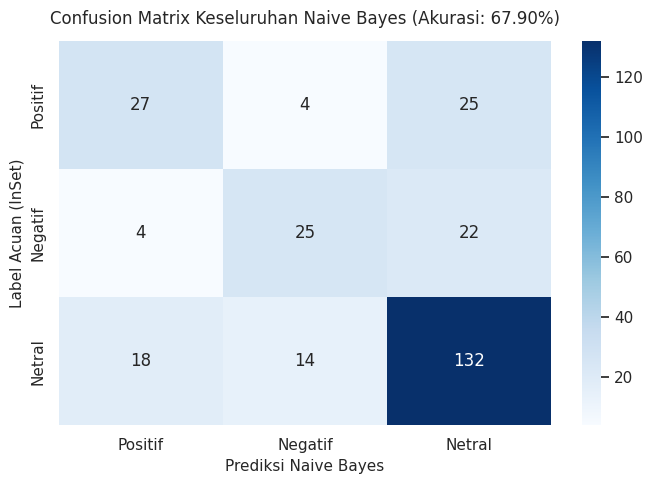

In [ ]:
# Pelatihan Naive Bayes
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train_sent)

# Prediksi pada Data Uji Alami
y_pred_nb = nb_model.predict(X_test_tfidf)
test_df['Prediksi_NB'] = y_pred_nb

# Perhitungan Metrik Keseluruhan
acc_overall = accuracy_score(y_test_sent, y_pred_nb)
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test_sent, y_pred_nb, average='macro', zero_division=0)
p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test_sent, y_pred_nb, average='weighted', zero_division=0)
n_test_total = len(test_df)

print("=" * 70)
print("HASIL EVALUASI KESELURUHAN MODEL NAIVE BAYES (DATA UJI ALAMI)")
print("=" * 70)
print(f"Jumlah Sampel Data Uji (N test) : {n_test_total}")
print(f"Akurasi (Accuracy)             : {acc_overall * 100:.2f}%")
print(f"Macro Precision                : {p_macro * 100:.2f}%")
print(f"Macro Recall                   : {r_macro * 100:.2f}%")
print(f"Macro F1-Score                 : {f1_macro * 100:.2f}%")
print(f"Weighted F1-Score              : {f1_weighted * 100:.2f}%")
print("=" * 70)

print(); print("Laporan Klasifikasi Detail:")
print(classification_report(y_test_sent, y_pred_nb, zero_division=0))

# Visualisasi Confusion Matrix Keseluruhan
labels_sent = ['Positif', 'Negatif', 'Netral']
cm_overall = confusion_matrix(y_test_sent, y_pred_nb, labels=labels_sent)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_overall, annot=True, fmt='d', cmap='Blues', xticklabels=labels_sent, yticklabels=labels_sent)
plt.title(f'Confusion Matrix Keseluruhan Naive Bayes (Akurasi: {acc_overall*100:.2f}%)', fontsize=12, pad=12)
plt.xlabel('Prediksi Naive Bayes', fontsize=11)
plt.ylabel('Label Acuan (InSet)', fontsize=11)
plt.tight_layout()
plt.show()


EVALUASI PERFORMA NAIVE BAYES PER KATEGORI ASPEK TPA SUWUNG


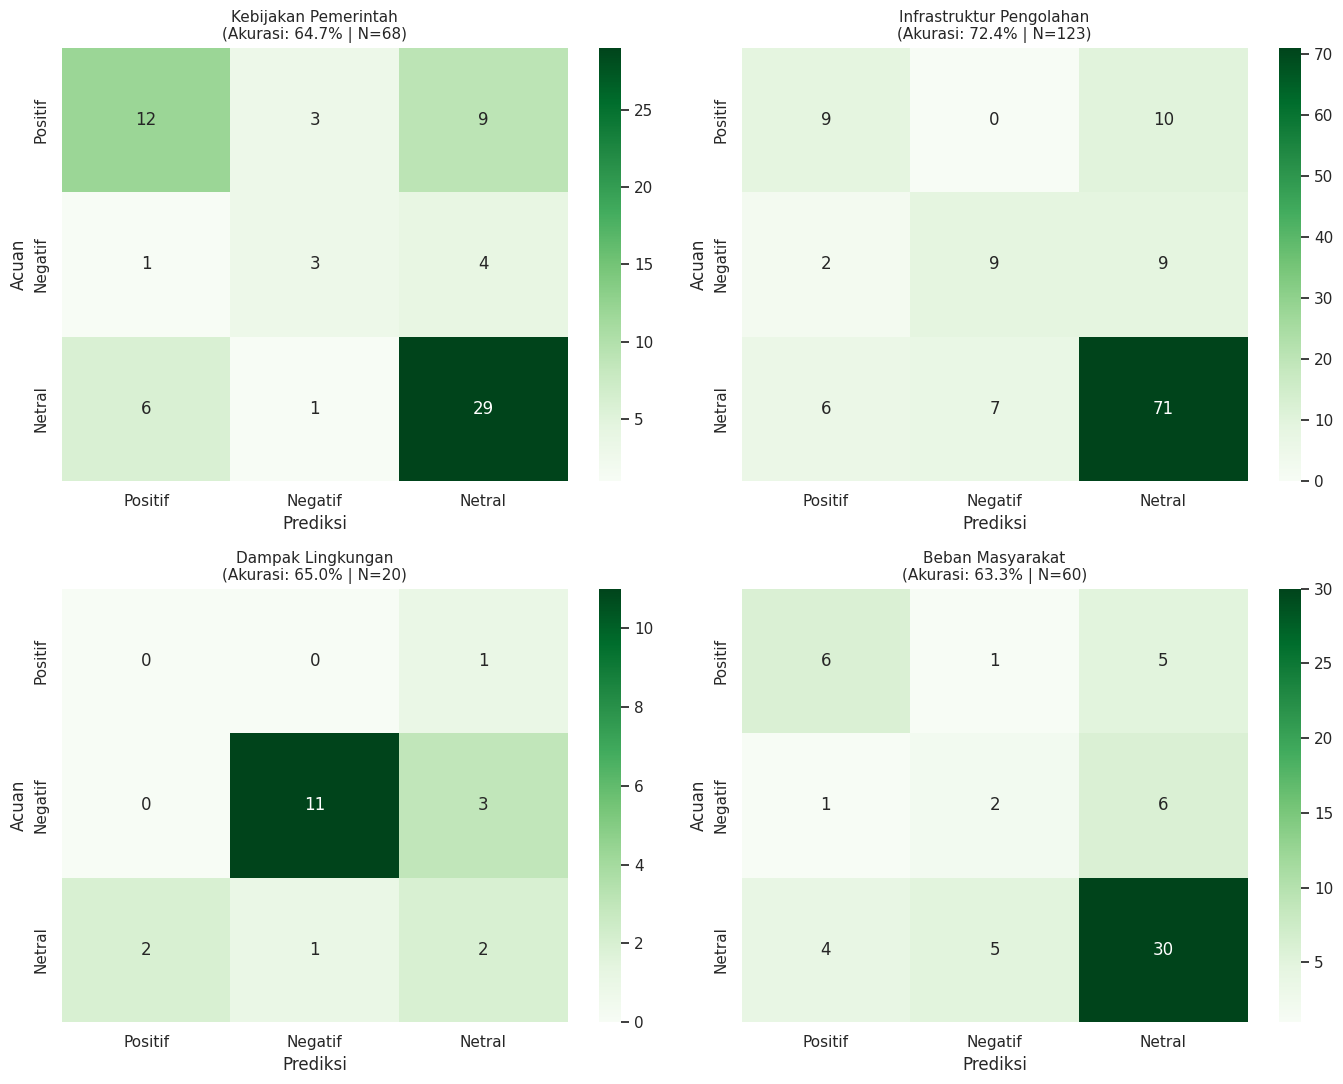


TABEL RINGKASAN METRIK EVALUASI NAIVE BAYES PER KATEGORI ASPEK


,Kategori Aspek,Akurasi (%),Macro Precision (%),Macro Recall (%),Macro F1-Score (%),Jumlah Data Uji (N)
0,Kebijakan Pemerintah,64.71,58.35,56.02,56.72,68
1,Infrastruktur Pengolahan,72.36,62.69,58.96,60.54,123
2,Dampak Lingkungan,65.00,41.67,39.52,40.33,20
3,Beban Masyarakat,63.33,50.91,49.72,50.23,60


In [ ]:
aspect_eval_rows = []
labels_sent = ['Positif', 'Negatif', 'Netral']

print("=" * 70)
print("EVALUASI PERFORMA NAIVE BAYES PER KATEGORI ASPEK TPA SUWUNG")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for i, aspect_name in enumerate(aspect_keywords.keys()):
    sub_test = test_df[test_df['Aspek'] == aspect_name]
    n_test_aspect = len(sub_test)

    if n_test_aspect > 0:
        y_true_sub = sub_test['Sentimen']
        y_pred_sub = sub_test['Prediksi_NB']

        acc_asp = accuracy_score(y_true_sub, y_pred_sub)
        p_asp, r_asp, f1_asp, _ = precision_recall_fscore_support(y_true_sub, y_pred_sub, average='macro', zero_division=0)

        aspect_eval_rows.append({
            'Kategori Aspek': aspect_name,
            'Akurasi (%)': round(acc_asp * 100, 2),
            'Macro Precision (%)': round(p_asp * 100, 2),
            'Macro Recall (%)': round(r_asp * 100, 2),
            'Macro F1-Score (%)': round(f1_asp * 100, 2),
            'Jumlah Data Uji (N)': n_test_aspect
        })

        # Plot Confusion Matrix
        cm_sub = confusion_matrix(y_true_sub, y_pred_sub, labels=labels_sent)
        sns.heatmap(cm_sub, annot=True, fmt='d', cmap='Greens', ax=axes[i],
                    xticklabels=labels_sent, yticklabels=labels_sent)
        axes[i].set_title(f"{aspect_name}\n(Akurasi: {acc_asp*100:.1f}% | N={n_test_aspect})", fontsize=11)
        axes[i].set_xlabel('Prediksi')
        axes[i].set_ylabel('Acuan')
    else:
        axes[i].set_title(f"{aspect_name} (Tidak ada data uji)", fontsize=11)

plt.tight_layout()
plt.show()

# Buat DataFrame Rangkuman Evaluasi Per Aspek
df_eval_aspect = pd.DataFrame(aspect_eval_rows)
print(); print( "=" * 70)
print("TABEL RINGKASAN METRIK EVALUASI NAIVE BAYES PER KATEGORI ASPEK")
print("=" * 70)
display(df_eval_aspect)

df_eval_aspect.to_excel("evaluasi_naive_bayes_per_aspek.xlsx", index=False)


In [ ]:
# 1. Konfigurasi Device (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Menggunakan perangkat komputasi: {device}")

# 2. Inisialisasi Tokenizer IndoBERT
PRE_TRAINED_MODEL_NAME = 'indobenchmark/indobert-base-p2'
tokenizer = AutoTokenizer.from_pretrained(PRE_TRAINED_MODEL_NAME)

# 3. Class Dataset PyTorch untuk IndoBERT
class ABSAJointDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'text': text,
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Label Joint Task Numerik (0 sampai 11) Sesuai Tabel 3.8
train_texts = train_df_balanced['Komentar_Bersih'].values
train_labels = train_df_balanced['Joint_Label_ID'].values

test_texts = test_df['Komentar_Bersih'].values
test_labels = test_df['Joint_Label_ID'].values

BATCH_SIZE = 16
MAX_LEN = 128

train_dataset = ABSAJointDataset(train_texts, train_labels, tokenizer, MAX_LEN)
test_dataset = ABSAJointDataset(test_texts, test_labels, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Data Latih IndoBERT Siap: {len(train_dataset)} sampel")
print(f"Data Uji IndoBERT Siap  : {len(test_dataset)} sampel")


[INFO] Menggunakan perangkat komputasi: cuda


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Data Latih IndoBERT Siap: 1974 sampel
Data Uji IndoBERT Siap  : 271 sampel


In [ ]:
NUM_CLASSES = 12
model = AutoModelForSequenceClassification.from_pretrained(
    PRE_TRAINED_MODEL_NAME,
    num_labels=NUM_CLASSES
)
model = model.to(device)

# Konfigurasi Pelatihan (20 Epoch sesuai revisi)
EPOCHS = 20
optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

loss_fn = nn.CrossEntropyLoss().to(device)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
best_model_weights = None

print("=" * 70)
print(f"MEMULAI FINE-TUNING INDOBERT (12 KELAS JOINT TASK) - {EPOCHS} EPOCH")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    # ------------------ FASE TRAINING ------------------
    model.train()
    total_train_loss = 0
    correct_train = 0
    total_train = 0

    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        _, preds = torch.max(logits, dim=1)
        total_train_loss += loss.item() * labels.size(0)
        correct_train += torch.sum(preds == labels).item()
        total_train += labels.size(0)

    train_loss = total_train_loss / total_train
    train_acc = correct_train / total_train

    # ------------------ FASE EVALUASI VALIDASI ------------------
    model.eval()
    total_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            _, preds = torch.max(logits, dim=1)
            total_val_loss += loss.item() * labels.size(0)
            correct_val += torch.sum(preds == labels).item()
            total_val += labels.size(0)

    val_loss = total_val_loss / total_val
    val_acc = correct_val / total_val

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Simpan model terbaik untuk mencegah overfitting
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        status_save = "★ BEST"
    else:
        status_save = ""

    if epoch % 2 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"Epoch [{epoch:2d}/{EPOCHS}] | Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | Val Loss: {val_loss:.4f} (Acc: {val_acc*100:.2f}%) {status_save}")

# Muat bobot model terbaik
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print(); print("[SUKSES] Memuat bobot model IndoBERT terbaik berdasarkan Validation Loss terendah.")


[transformers] You passed `num_labels=12` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

MEMULAI FINE-TUNING INDOBERT (12 KELAS JOINT TASK) - 20 EPOCH
Epoch [ 1/20] | Train Loss: 2.2756 (Acc: 21.43%) | Val Loss: 1.9901 (Acc: 39.11%) ★ BEST
Epoch [ 2/20] | Train Loss: 1.5212 (Acc: 46.86%) | Val Loss: 1.4682 (Acc: 52.77%) ★ BEST
Epoch [ 4/20] | Train Loss: 0.7762 (Acc: 64.29%) | Val Loss: 1.2498 (Acc: 57.93%) 
Epoch [ 6/20] | Train Loss: 0.6601 (Acc: 65.40%) | Val Loss: 1.1977 (Acc: 59.41%) ★ BEST
Epoch [ 8/20] | Train Loss: 0.6109 (Acc: 66.31%) | Val Loss: 1.1804 (Acc: 60.89%) ★ BEST
Epoch [10/20] | Train Loss: 0.5769 (Acc: 67.58%) | Val Loss: 1.1754 (Acc: 61.25%) 
Epoch [12/20] | Train Loss: 0.5603 (Acc: 66.97%) | Val Loss: 1.1583 (Acc: 61.62%) 
Epoch [14/20] | Train Loss: 0.5442 (Acc: 68.19%) | Val Loss: 1.1708 (Acc: 61.25%) 
Epoch [16/20] | Train Loss: 0.5294 (Acc: 68.95%) | Val Loss: 1.1544 (Acc: 61.99%) 
Epoch [18/20] | Train Loss: 0.5190 (Acc: 70.42%) | Val Loss: 1.1527 (Acc: 61.99%) 
Epoch [20/20] | Train Loss: 0.5082 (Acc: 70.47%) | Val Loss: 1.1531 (Acc: 61.99%) 



HASIL EVALUASI OPTIMAL MODEL INDOBERT PADA DATA UJI
Akurasi Joint Task (12 Kelas)    : 61.25%
Macro F1-Score Joint Task        : 46.06%
----------------------------------------------------------------------
Akurasi Sentimen (ABSA)          : 86.72%
Macro F1-Score Sentimen (ABSA)   : 84.52%


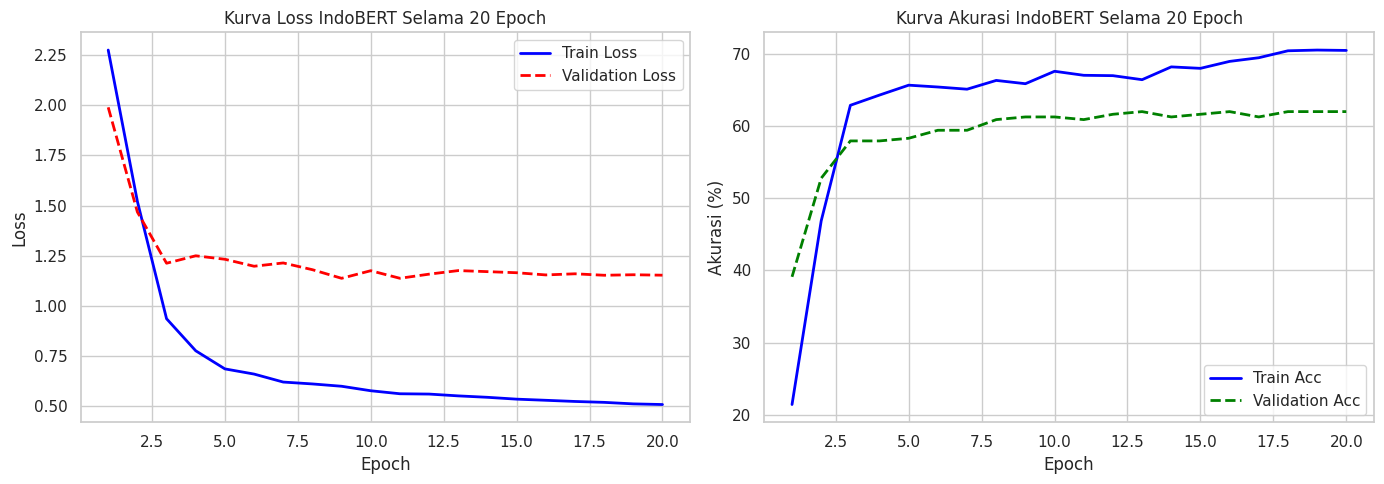


TABEL KOMPARASI PERFORMA: NAIVE BAYES VS INDOBERT


,Metrik,Naive Bayes (TF-IDF),IndoBERT (Fine-Tuning)
0,Akurasi Sentimen (%),67.90,86.72
1,Macro Precision (%),62.33,83.27
2,Macro Recall (%),59.24,86.12
3,Macro F1-Score (%),60.53,84.52


In [ ]:
model.eval()
all_preds = []
all_trues = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_trues.extend(labels.cpu().numpy())

test_df['Prediksi_IndoBERT_ID'] = all_preds
test_df['Prediksi_IndoBERT'] = [joint_task_id_to_label[p] for p in all_preds]
# Ekstrak sentimen dari prediksi Joint IndoBERT
test_df['Prediksi_IndoBERT_Sentimen'] = test_df['Prediksi_IndoBERT'].apply(lambda x: x.split('_')[1] if '_' in x else 'Netral')

# Hitung Akurasi Joint Task 12 Kelas
joint_acc = accuracy_score(all_trues, all_preds)
p_macro_j, r_macro_j, f1_macro_j, _ = precision_recall_fscore_support(all_trues, all_preds, average='macro', zero_division=0)

# Hitung Akurasi Sentimen Saja (ABSA)
sent_acc_bert = accuracy_score(test_df['Sentimen'], test_df['Prediksi_IndoBERT_Sentimen'])
p_macro_s, r_macro_s, f1_macro_s, _ = precision_recall_fscore_support(test_df['Sentimen'], test_df['Prediksi_IndoBERT_Sentimen'], average='macro', zero_division=0)

print("=" * 70)
print("HASIL EVALUASI OPTIMAL MODEL INDOBERT PADA DATA UJI")
print("=" * 70)
print(f"Akurasi Joint Task (12 Kelas)    : {joint_acc * 100:.2f}%")
print(f"Macro F1-Score Joint Task        : {f1_macro_j * 100:.2f}%")
print("-" * 70)
print(f"Akurasi Sentimen (ABSA)          : {sent_acc_bert * 100:.2f}%")
print(f"Macro F1-Score Sentimen (ABSA)   : {f1_macro_s * 100:.2f}%")
print("=" * 70)

# Visualisasi Kurva Training Loss & Accuracy
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(range(1, EPOCHS + 1), history['train_loss'], label='Train Loss', color='blue', lw=2)
ax[0].plot(range(1, EPOCHS + 1), history['val_loss'], label='Validation Loss', color='red', lw=2, linestyle='--')
ax[0].set_title('Kurva Loss IndoBERT Selama 20 Epoch', fontsize=12)
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(range(1, EPOCHS + 1), [a*100 for a in history['train_acc']], label='Train Acc', color='blue', lw=2)
ax[1].plot(range(1, EPOCHS + 1), [a*100 for a in history['val_acc']], label='Validation Acc', color='green', lw=2, linestyle='--')
ax[1].set_title('Kurva Akurasi IndoBERT Selama 20 Epoch', fontsize=12)
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Akurasi (%)')
ax[1].legend()

plt.tight_layout()
plt.show()

# Tabel Perbandingan Naive Bayes vs IndoBERT
comp_models = pd.DataFrame({
    'Metrik': ['Akurasi Sentimen (%)', 'Macro Precision (%)', 'Macro Recall (%)', 'Macro F1-Score (%)'],
    'Naive Bayes (TF-IDF)': [round(acc_overall*100, 2), round(p_macro*100, 2), round(r_macro*100, 2), round(f1_macro*100, 2)],
    'IndoBERT (Fine-Tuning)': [round(sent_acc_bert*100, 2), round(p_macro_s*100, 2), round(r_macro_s*100, 2), round(f1_macro_s*100, 2)]
})
print(); print( "=" * 70)
print("TABEL KOMPARASI PERFORMA: NAIVE BAYES VS INDOBERT")
print("=" * 70)
display(comp_models)


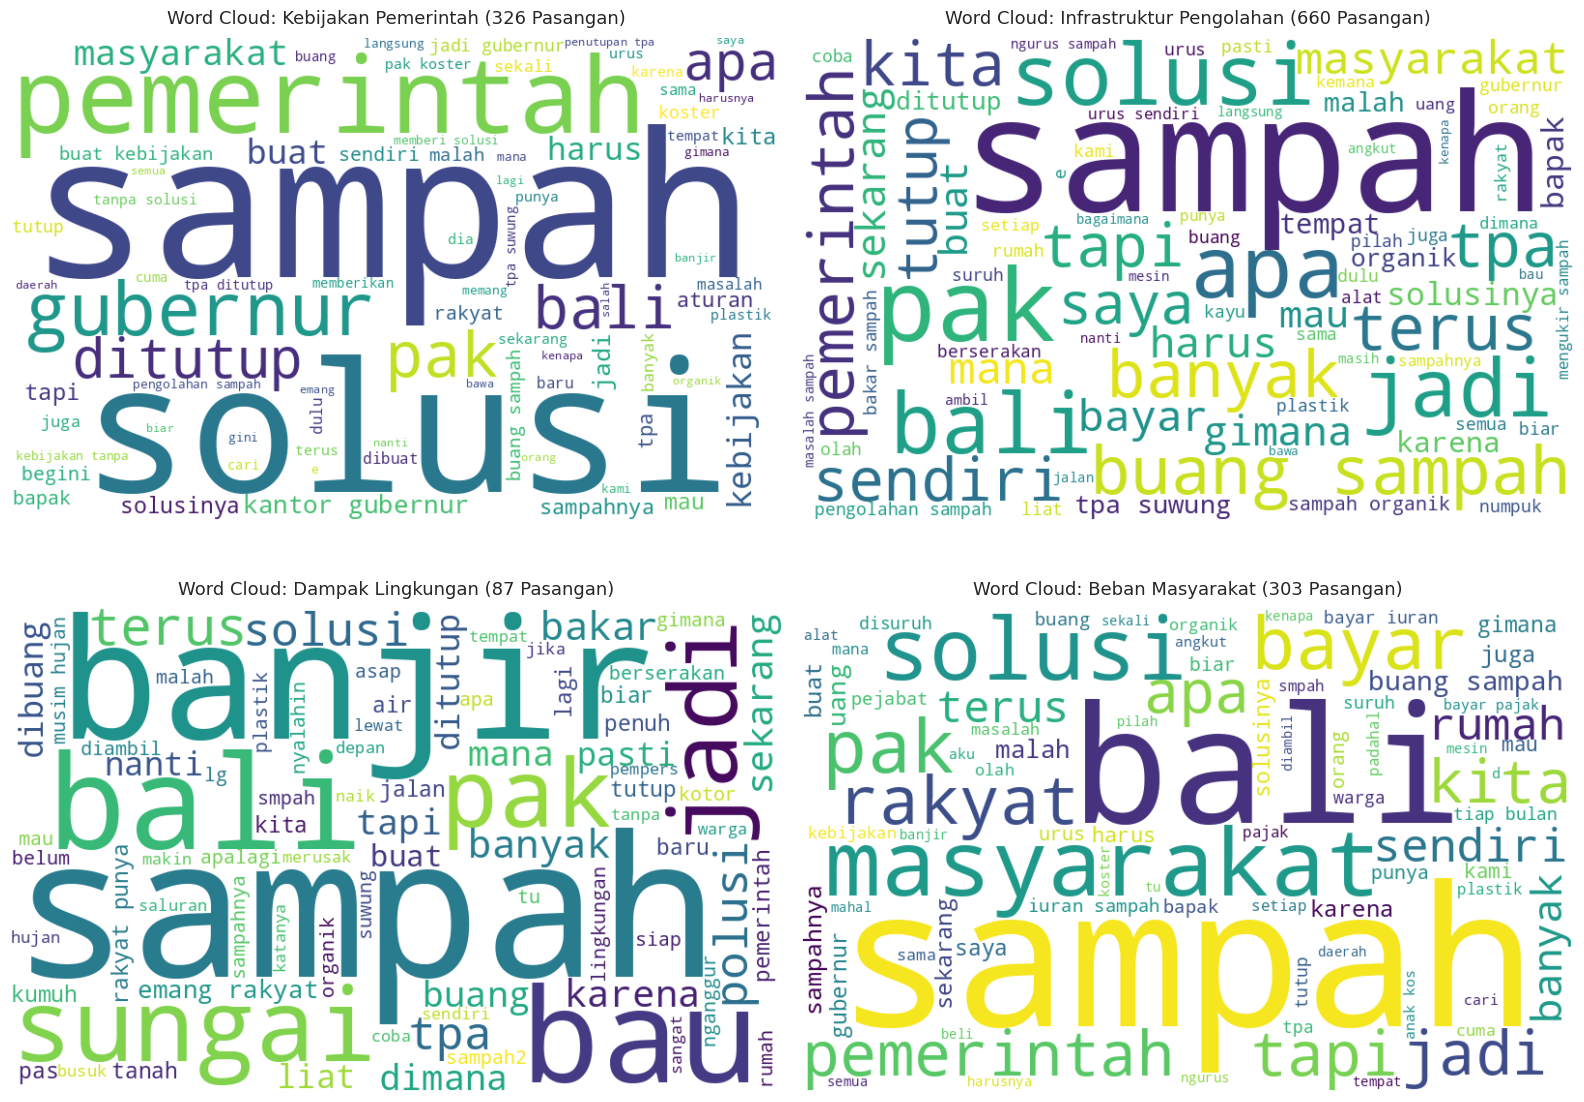

In [ ]:
# Stopwords umum percakapan TikTok & konteks Bali
stopwords_custom = set([
    'yang', 'di', 'ke', 'dari', 'ini', 'itu', 'dan', 'atau', 'untuk', 'pada',
    'dengan', 'adalah', 'akan', 'bisa', 'ada', 'tidak', 'gak', 'ga', 'bukan',
    'jangan', 'kalau', 'kalo', 'ya', 'aja', 'saja', 'nih', 'deh', 'dong',
    'lah', 'nya', 'sih', 'kan', 'kok', 'banget', 'dah', 'udah', 'sudah', 'ne', 'bli'
])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (aspect_name, kws) in enumerate(aspect_keywords.items()):
    aspect_texts = df_pairs[df_pairs['Aspek'] == aspect_name]['Komentar_Bersih']
    all_text = ' '.join(aspect_texts)

    if len(all_text.strip()) > 0:
        wc = WordCloud(
            width=800,
            height=500,
            background_color='white',
            stopwords=stopwords_custom,
            colormap='viridis',
            max_words=80
        ).generate(all_text)

        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f'Word Cloud: {aspect_name} ({len(aspect_texts)} Pasangan)', fontsize=13, pad=10)
        axes[i].axis('off')

plt.tight_layout()
plt.show()


<Figure size 1200x600 with 0 Axes>

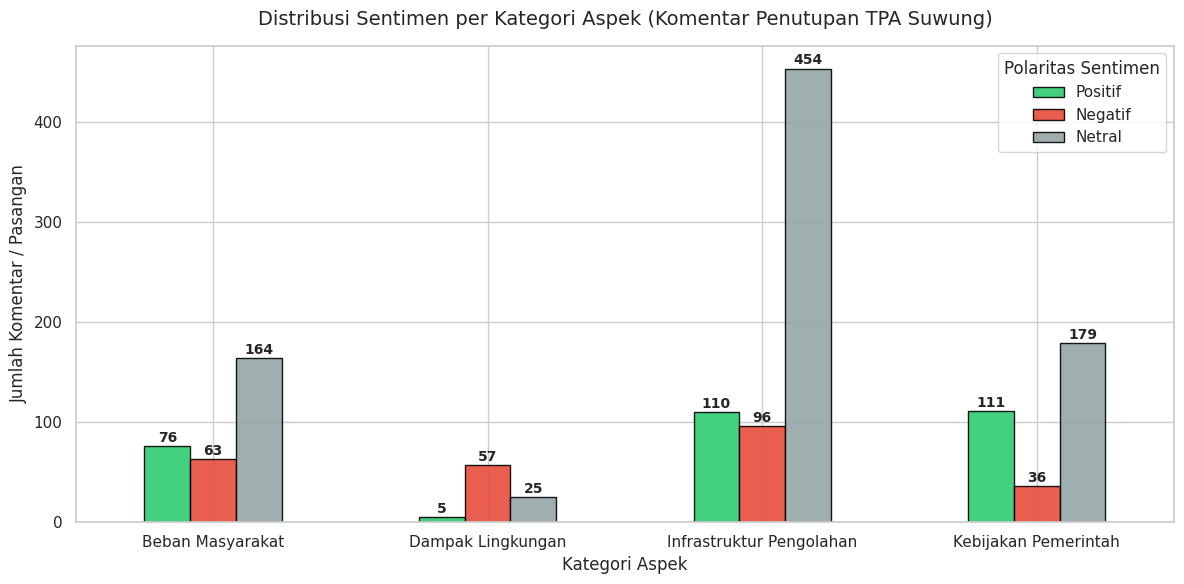

In [ ]:
plt.figure(figsize=(12, 6))
chart_data = df_pairs.groupby(['Aspek', 'Sentimen']).size().unstack(fill_value=0)
chart_data = chart_data[['Positif', 'Negatif', 'Netral']]

colors = ['#2ecc71', '#e74c3c', '#95a5a6']
ax = chart_data.plot(kind='bar', stacked=False, figsize=(12, 6), color=colors, edgecolor='black', alpha=0.9)
plt.title('Distribusi Sentimen per Kategori Aspek (Komentar Penutupan TPA Suwung)', fontsize=14, pad=15)
plt.xlabel('Kategori Aspek', fontsize=12)
plt.ylabel('Jumlah Komentar / Pasangan', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.legend(title='Polaritas Sentimen', fontsize=11)

for p in ax.patches:
    val = int(p.get_height())
    if val > 0:
        ax.annotate(str(val), (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()


In [ ]:
sample_audit = test_df[['ID_Komentar', 'Komentar_Asli', 'Aspek', 'Sentimen', 'Prediksi_NB', 'Prediksi_IndoBERT_Sentimen']].head(25).copy()
sample_audit.columns = ['ID', 'Komentar Asli', 'Aspek', 'Acuan (InSet)', 'Prediksi NB', 'Prediksi IndoBERT']
sample_audit['Status NB'] = np.where(sample_audit['Acuan (InSet)'] == sample_audit['Prediksi NB'], 'COCOK', 'BERBEDA')
sample_audit['Status IndoBERT'] = np.where(sample_audit['Acuan (InSet)'] == sample_audit['Prediksi IndoBERT'], 'COCOK', 'BERBEDA')

print("=" * 70)
print("TABEL AUDIT CONTOH HASIL PREDIKSI DATA UJI (NAIVE BAYES & INDOBERT)")
print("=" * 70)
display(sample_audit)

# Simpan tabel hasil prediksi data uji lengkap
output_test_audit = "hasil_prediksi_data_uji_lengkap.xlsx"
test_df.to_excel(output_test_audit, index=False)
print(f"[TERSIMPAN] Hasil prediksi data uji lengkap disimpan ke: {output_test_audit}")


TABEL AUDIT CONTOH HASIL PREDIKSI DATA UJI (NAIVE BAYES & INDOBERT)


,ID,Komentar Asli,Aspek,Acuan (InSet),Prediksi NB,Prediksi IndoBERT,Status NB,Status IndoBERT
0,28,Saya sedih sampah di tempat kerja aaya sudah n...,Infrastruktur Pengolahan,Netral,Netral,Netral,COCOK,COCOK
1,40,kalo gitu gubernur nya harusnya cari solusi da...,Kebijakan Pemerintah,Netral,Positif,Positif,BERBEDA,BERBEDA
2,41,aku art di Nusa dua.. capek memilah.. lalu nan...,Kebijakan Pemerintah,Netral,Netral,Netral,COCOK,COCOK
3,45,"Sampah plastik ne anggo krupuk, sampah daun an...",Infrastruktur Pengolahan,Netral,Netral,Netral,COCOK,COCOK
4,52,Terus sampah nya di bawa kemana?,Infrastruktur Pengolahan,Netral,Netral,Netral,COCOK,COCOK
5,59,Cuma d Bali kayaknya urusn sampah ribet bngt,Infrastruktur Pengolahan,Negatif,Negatif,Negatif,COCOK,COCOK
6,59,Cuma d Bali kayaknya urusn sampah ribet bngt,Beban Masyarakat,Negatif,Negatif,Negatif,COCOK,COCOK
7,64,"ini udah ada solusi, kenapa bukan pemerintah s...",Kebijakan Pemerintah,Positif,Negatif,Positif,BERBEDA,COCOK
8,64,"ini udah ada solusi, kenapa bukan pemerintah s...",Beban Masyarakat,Positif,Negatif,Positif,BERBEDA,COCOK
9,77,tps tidak akan mampu menyelesaikan semua sampah,Infrastruktur Pengolahan,Netral,Netral,Netral,COCOK,COCOK


[TERSIMPAN] Hasil prediksi data uji lengkap disimpan ke: hasil_prediksi_data_uji_lengkap.xlsx


In [ ]:
def analisa_komentar_tpa_suwung(komentar_baru):
    print("=" * 70)
    print("ANALISIS KOMENTAR BARU TENTANG TPA SUWUNG")
    print("=" * 70)
    print(f"Komentar Masukan: \"{komentar_baru}\"")

    clean = clean_text_preserving_negations(komentar_baru)
    print(f"Teks Bersih     : \"{clean}\"")

    # 1. Deteksi Aspek
    detected = []
    for aspect, kws in aspect_keywords.items():
        for kw in kws:
            pattern = r'\b' + re.escape(kw) + r'\b'
            if re.search(pattern, clean):
                detected.append(aspect)
                break

    if not detected:
        print("[HASIL] Komentar ini tidak terdeteksi membahas 4 Aspek TPA Suwung.")
        return

    print(f"Aspek Terdeteksi: {', '.join(detected)}")

    # 2. Prediksi Sentimen Naive Bayes
    vec = tfidf_vectorizer.transform([clean])
    pred_nb = nb_model.predict(vec)[0]

    # 3. Prediksi IndoBERT (Joint Task)
    encoding = tokenizer(
        clean,
        add_special_tokens=True,
        max_length=MAX_LEN,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    model.eval()
    with torch.no_grad():
        out = model(input_ids=encoding['input_ids'].to(device), attention_mask=encoding['attention_mask'].to(device))
        pred_joint_id = torch.argmax(out.logits, dim=1).item()
        pred_joint_label = joint_task_id_to_label[pred_joint_id]
        pred_bert_sent = pred_joint_label.split('_')[1] if '_' in pred_joint_label else 'Netral'

    print(f"Prediksi Sentimen (Naive Bayes) : {pred_nb}")
    print(f"Prediksi Joint Task (IndoBERT)  : {pred_joint_label}")
    print(f"Prediksi Sentimen (IndoBERT)    : {pred_bert_sent}")
    print("=" * 70)

# Uji Coba Beberapa Contoh Komentar Percakapan Warga Bali
contoh_komentar_uji = [
    "ije ngalih pis anggo meli alat ne",
    "pak ne sebatas ngomong doen sing ade solusi ne",
    "men dije jani tiang ngutang mis? di kantor gubernur?",
    "Gaya gen ngae kebijakan tapi sing ade solusi arah gubernur bali",
    "pemerintah bagus sekali menutup tpa suwung agar polusi dan bau sampah berkurang",
    "terus warga buang sampah kemana kalau tpst belum siap, malah nambah biaya iuran"
]

for teks in contoh_komentar_uji:
    analisa_komentar_tpa_suwung(teks)
    print(); print("")


ANALISIS KOMENTAR BARU TENTANG TPA SUWUNG
Komentar Masukan: "ije ngalih pis anggo meli alat ne"
Teks Bersih     : "ke mana cari uang untuk beli alat ini"
Aspek Terdeteksi: Infrastruktur Pengolahan, Beban Masyarakat
Prediksi Sentimen (Naive Bayes) : Netral
Prediksi Joint Task (IndoBERT)  : Beban Masyarakat_Netral
Prediksi Sentimen (IndoBERT)    : Netral


ANALISIS KOMENTAR BARU TENTANG TPA SUWUNG
Komentar Masukan: "pak ne sebatas ngomong doen sing ade solusi ne"
Teks Bersih     : "pak ini sebatas ngomong saja tidak ada solusi ini"
[HASIL] Komentar ini tidak terdeteksi membahas 4 Aspek TPA Suwung.


ANALISIS KOMENTAR BARU TENTANG TPA SUWUNG
Komentar Masukan: "men dije jani tiang ngutang mis? di kantor gubernur?"
Teks Bersih     : "kalau di mana sekarang saya buang sampah di kantor gubernur"
Aspek Terdeteksi: Kebijakan Pemerintah, Infrastruktur Pengolahan
Prediksi Sentimen (Naive Bayes) : Netral
Prediksi Joint Task (IndoBERT)  : Infrastruktur Pengolahan_Netral
Prediksi Sentimen (IndoBERT)

In [ ]:
drive_save_dir = '/content/drive/MyDrive/INDOBERT/'

output_files = [
    'dataset_pasangan_komentar_aspek_suwung.xlsx',
    'evaluasi_naive_bayes_per_aspek.xlsx',
    'hasil_prediksi_data_uji_lengkap.xlsx'
]

print("=" * 70)
print("STATUS PENYIMPANAN ARTIFAK HASIL PENELITIAN")
print("=" * 70)

if os.path.exists(drive_save_dir):
    for f in output_files:
        if os.path.exists(f):
            dest = os.path.join(drive_save_dir, f)
            pd.read_excel(f).to_excel(dest, index=False)
            print(f"[SUKSES DISINKRON] {f} -> {dest}")
else:
    print(f"[INFO] Folder Google Drive '{drive_save_dir}' belum tersedia. File tersimpan aman di workspace Colab.")
    for f in output_files:
        if os.path.exists(f):
            print(f"- {f} (Siap diunduh dari tab Files Colab)")

print("=" * 70)
print("SELURUH TAHAPAN REVISI SKRIPSI TPA SUWUNG SELESAI DENGAN SEMPURNA!")
print("=" * 70)


STATUS PENYIMPANAN ARTIFAK HASIL PENELITIAN
[SUKSES DISINKRON] dataset_pasangan_komentar_aspek_suwung.xlsx -> /content/drive/MyDrive/INDOBERT/dataset_pasangan_komentar_aspek_suwung.xlsx
[SUKSES DISINKRON] evaluasi_naive_bayes_per_aspek.xlsx -> /content/drive/MyDrive/INDOBERT/evaluasi_naive_bayes_per_aspek.xlsx
[SUKSES DISINKRON] hasil_prediksi_data_uji_lengkap.xlsx -> /content/drive/MyDrive/INDOBERT/hasil_prediksi_data_uji_lengkap.xlsx
SELURUH TAHAPAN REVISI SKRIPSI TPA SUWUNG SELESAI DENGAN SEMPURNA!
